<a href="https://colab.research.google.com/github/apiswrld/Tugas-Klasifikasi/blob/main/Tugas_Klasifikasi_Diabetes_Haffiz_Rizki_R.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas Individu: Studi Kasus Klasifikasi
## Klasifikasi Risiko Diabetes pada Perempuan Suku Pima Menggunakan Machine Learning

**Nama:** Haffiz Rizki Ramadhan  
**NIM:** 2404010008  
**Mata Kuliah:** Data Mining

## 1. Latar Belakang dan Permasalahan

Diabetes melitus adalah penyakit kronis yang terjadi ketika tubuh tidak dapat mengatur kadar gula darah dengan baik. Penyakit ini sering tidak bergejala pada tahap awal, sehingga banyak penderita baru terdiagnosis setelah muncul komplikasi seperti gangguan ginjal, saraf, mata, dan jantung. Semakin cepat seseorang diketahui berisiko, semakin besar peluang pencegahan dan penanganan dini.

Pemeriksaan awal biasanya memakai data klinis sederhana seperti kadar glukosa, tekanan darah, indeks massa tubuh (BMI), dan usia. Menilai seluruh faktor ini sekaligus untuk banyak pasien membutuhkan waktu dan tenaga medis.

**Permasalahan:** bagaimana membangun model *machine learning* yang dapat memprediksi apakah seorang pasien **menderita diabetes (1)** atau **tidak (0)** berdasarkan 8 pengukuran klinis, sehingga dapat membantu penyaringan awal (*screening*)?

Ini adalah masalah **klasifikasi biner** (dua kelas). Dalam konteks *screening*, kesalahan yang paling merugikan adalah **pasien diabetes yang diprediksi sehat (*false negative*)**, sehingga selain akurasi, **recall kelas diabetes** menjadi metrik utama yang diperhatikan.

## 2. Dataset

Dataset yang digunakan adalah **Pima Indians Diabetes Database**, yang berasal dari *National Institute of Diabetes and Digestive and Kidney Diseases* (NIDDK), Amerika Serikat. Data berisi pasien perempuan berusia minimal 21 tahun keturunan suku Pima.

| Aspek | Keterangan |
|---|---|
| Sumber asli | NIDDK, dipublikasikan melalui UCI Machine Learning Repository dan Kaggle |
| Tautan sumber (dapat dilihat langsung) | https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database |
| Berkas data yang dimuat di notebook ini | https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv (salinan CSV terbuka, dapat dibuka langsung di browser) |
| Jumlah data | 768 pasien |
| Jumlah fitur | 8 fitur numerik |
| Target | `Outcome`: 1 = diabetes, 0 = tidak diabetes |

**Deskripsi fitur:**

| Fitur | Keterangan |
|---|---|
| `Pregnancies` | Jumlah kehamilan |
| `Glucose` | Kadar glukosa plasma (tes toleransi glukosa 2 jam) |
| `BloodPressure` | Tekanan darah diastolik (mm Hg) |
| `SkinThickness` | Ketebalan lipatan kulit trisep (mm) |
| `Insulin` | Kadar insulin serum 2 jam (mu U/ml) |
| `BMI` | Indeks massa tubuh (kg/m²) |
| `DiabetesPedigreeFunction` | Skor riwayat diabetes pada keluarga |
| `Age` | Usia (tahun) |

Berkas CSV ini **tidak memiliki baris header**, sehingga nama kolom dipasang manual sesuai dokumentasi dataset.

## 3. Metode Klasifikasi yang Digunakan

Pada studi kasus ini dibandingkan **lima algoritma klasifikasi**, lalu model terbaik dipilih dan dioptimalkan:

| Algoritma | Ide singkat |
|---|---|
| **Logistic Regression** | Model linear yang menghitung probabilitas suatu data masuk ke kelas tertentu memakai fungsi sigmoid. Koefisiennya mudah ditafsirkan. |
| **Naive Bayes (Gaussian)** | Menghitung probabilitas kelas dengan teorema Bayes, dengan asumsi setiap fitur saling bebas dan berdistribusi normal. |
| **K-Nearest Neighbors (KNN)** | Mengklasifikasikan data berdasarkan kelas mayoritas dari *k* tetangga terdekat. |
| **Random Forest** | Gabungan banyak *decision tree* yang hasilnya divoting, sehingga lebih stabil dan tahan *overfitting*. |
| **Gradient Boosting** | Membangun pohon secara berurutan, tiap pohon baru memperbaiki kesalahan pohon sebelumnya. |

Model dinilai dengan **akurasi, precision, recall, F1-score, dan ROC-AUC**. Pemilihan model memakai **validasi silang 5-fold (ROC-AUC)** pada data latih agar tidak bergantung pada satu kali pembagian data.

## 4. Tahapan Penerapan

### 4.1 Import Library

In [ ]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, cross_val_predict, GridSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_STATE = 42

### 4.2 Memuat Dataset

Data dibaca langsung dari tautan CSV terbuka. Jika unduhan gagal (misalnya tidak ada koneksi), unduh berkas dari tautan di bagian 2, unggah ke Colab (ikon folder → Upload) dengan nama `pima-indians-diabetes.data.csv`, lalu jalankan ulang sel ini.

In [ ]:
kolom = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
         "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

try:
    df = pd.read_csv(URL, header=None, names=kolom)
    print("Data dimuat langsung dari sumber online.")
except Exception as e:
    print("Unduh langsung gagal:", type(e).__name__)
    if not os.path.exists("pima-indians-diabetes.data.csv"):
        raise FileNotFoundError("Unggah pima-indians-diabetes.data.csv ke Colab lalu jalankan ulang sel ini.")
    df = pd.read_csv("pima-indians-diabetes.data.csv", header=None, names=kolom)
    print("Data dimuat dari berkas lokal.")

print("Ukuran data (baris, kolom):", df.shape)
df.head()

Data dimuat langsung dari sumber online.
Ukuran data (baris, kolom): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### 4.3 Eksplorasi Data (EDA)

In [ ]:
df.info()
print()
print("Missing value (NaN) :", int(df.isnull().sum().sum()))
print("Baris duplikat      :", int(df.duplicated().sum()))
df.describe().T.round(2)

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing value (NaN) : 0
Baris duplikat      : 0


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.85,3.37,0.00,1.00,3.00,6.00,17.00
Glucose,768.0,120.89,31.97,0.00,99.00,117.00,140.25,199.00
BloodPressure,768.0,69.11,19.36,0.00,62.00,72.00,80.00,122.00
SkinThickness,768.0,20.54,15.95,0.00,0.00,23.00,32.00,99.00
Insulin,768.0,79.80,115.24,0.00,0.00,30.50,127.25,846.00
BMI,768.0,31.99,7.88,0.00,27.30,32.00,36.60,67.10
DiabetesPedigreeFunction,768.0,0.47,0.33,0.08,0.24,0.37,0.63,2.42
Age,768.0,33.24,11.76,21.00,24.00,29.00,41.00,81.00
Outcome,768.0,0.35,0.48,0.00,0.00,0.00,1.00,1.00


Outcome
Tidak diabetes    500
Diabetes          268
Name: count, dtype: int64

Outcome
0    65.1 %
1    34.9 %
Name: proportion, dtype: str


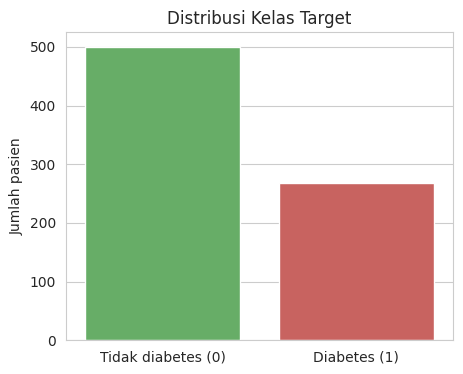

In [ ]:
# Distribusi kelas target
print(df["Outcome"].value_counts().rename({0: "Tidak diabetes", 1: "Diabetes"}))
print()
print((df["Outcome"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(5, 4))
sns.countplot(data=df, x="Outcome", hue="Outcome", palette=["#5cb85c", "#d9534f"], legend=False)
plt.xticks([0, 1], ["Tidak diabetes (0)", "Diabetes (1)"])
plt.title("Distribusi Kelas Target")
plt.xlabel(""); plt.ylabel("Jumlah pasien")
plt.show()

**Interpretasi:** data tidak seimbang secara ringan (sekitar dua pertiga pasien tidak diabetes). Karena itu pembagian data memakai *stratified split* agar proporsi kelas terjaga, dan evaluasi tidak hanya melihat akurasi.

#### Temuan penting: nilai 0 yang tidak masuk akal

Fitur seperti `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, dan `BMI` **tidak mungkin bernilai 0** pada manusia hidup. Nilai 0 pada kolom-kolom ini sebenarnya adalah **kode data hilang yang "menyamar"** (*hidden missing value*), sehingga `isnull()` tidak mendeteksinya. (Kolom `Pregnancies` boleh bernilai 0 karena memang bisa belum pernah hamil.)

In [ ]:
kolom_nol = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
ringkas = pd.DataFrame({
    "Jumlah nilai 0": (df[kolom_nol] == 0).sum(),
    "Persentase (%)": ((df[kolom_nol] == 0).mean() * 100).round(1),
})
ringkas

,Jumlah nilai 0,Persentase (%)
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


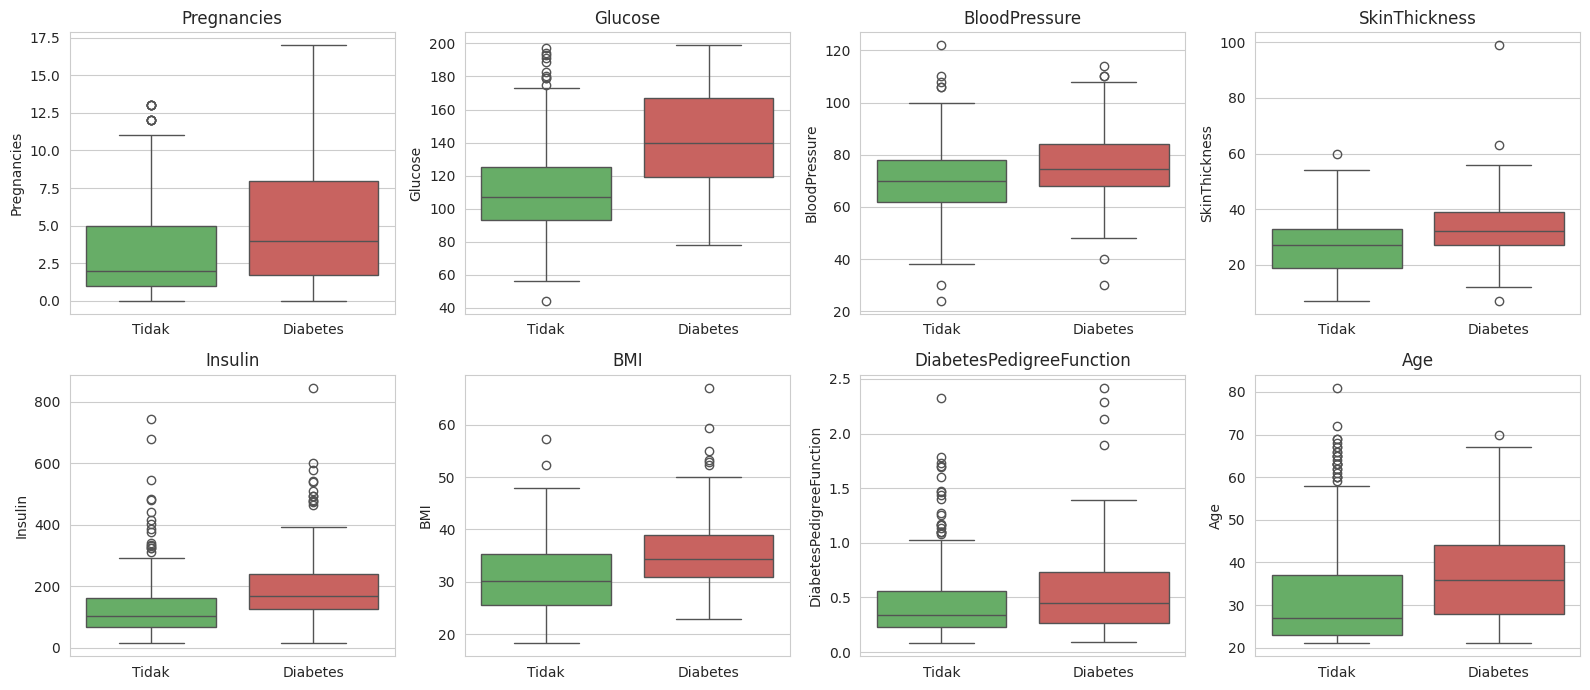

In [ ]:
# Perbandingan fitur antar kelas (nilai 0 tersembunyi diabaikan agar gambar tidak menyesatkan)
fitur = [c for c in df.columns if c != "Outcome"]
tampil = df.copy()
tampil[kolom_nol] = tampil[kolom_nol].replace(0, np.nan)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, f in zip(axes.ravel(), fitur):
    sns.boxplot(data=tampil, x="Outcome", y=f, hue="Outcome",
                palette=["#5cb85c", "#d9534f"], legend=False, ax=ax)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Tidak", "Diabetes"])
    ax.set_xlabel(""); ax.set_title(f)
plt.tight_layout(); plt.show()

**Interpretasi:** pasien diabetes cenderung memiliki `Glucose`, `BMI`, `Age`, dan `Insulin` yang lebih tinggi. Perbedaan `Glucose` antar kelas paling jelas, sehingga fitur ini diperkirakan paling informatif.

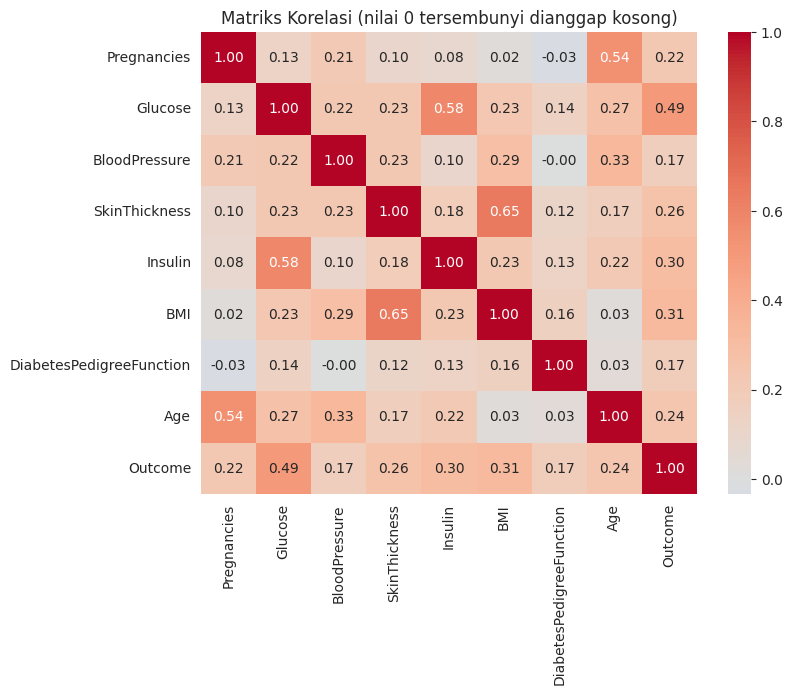

Korelasi fitur dengan Outcome:
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


In [ ]:
# Korelasi antar fitur dan dengan target
plt.figure(figsize=(8, 6))
sns.heatmap(tampil.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriks Korelasi (nilai 0 tersembunyi dianggap kosong)")
plt.show()

print("Korelasi fitur dengan Outcome:")
print(tampil.corr()["Outcome"].drop("Outcome").sort_values(ascending=False).round(3))

### 4.4 Preprocessing

1. **Nilai 0 tersembunyi → `NaN`** pada lima kolom di atas.
2. **Pembagian data** 80% latih dan 20% uji dengan `stratify=y`. Pembagian dilakukan **sebelum** imputasi dan scaling agar tidak terjadi *data leakage*.
3. **Imputasi median** (tahan terhadap outlier) dan **standardisasi** (`StandardScaler`) dimasukkan ke dalam `Pipeline`, sehingga nilai median dan statistik scaling hanya dipelajari dari data latih (dan dihitung ulang di tiap lipatan validasi silang).

In [ ]:
# 1) Nilai 0 tersembunyi -> NaN
df_bersih = df.copy()
df_bersih[kolom_nol] = df_bersih[kolom_nol].replace(0, np.nan)
print("Missing value setelah penandaan:")
print(df_bersih.isnull().sum()[lambda s: s > 0])

# 2) Pisahkan fitur dan target, lalu bagi data
X = df_bersih.drop(columns="Outcome")
y = df_bersih["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("\nData latih:", X_train.shape, "| Data uji:", X_test.shape)
print("Proporsi diabetes (latih):", round(y_train.mean(), 3), "| (uji):", round(y_test.mean(), 3))

Missing value setelah penandaan:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Data latih: (614, 8) | Data uji: (154, 8)
Proporsi diabetes (latih): 0.349 | (uji): 0.351


### 4.5 Pemodelan dan Validasi Silang

Tiap model dibungkus dalam `Pipeline` (imputasi → scaling bila perlu → model). Naive Bayes, Random Forest, dan Gradient Boosting tidak sensitif terhadap skala fitur sehingga tidak memakai scaler.

In [ ]:
def imputer():
    return SimpleImputer(strategy="median")

models = {
    "Logistic Regression": make_pipeline(imputer(), StandardScaler(),
                                         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    "Naive Bayes":         make_pipeline(imputer(), GaussianNB()),
    "KNN":                 make_pipeline(imputer(), StandardScaler(), KNeighborsClassifier()),
    "Random Forest":       make_pipeline(imputer(), RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)),
    "Gradient Boosting":   make_pipeline(imputer(), GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

hasil_cv = {}
for nama, model in models.items():
    r = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=["accuracy", "recall", "f1", "roc_auc"])
    hasil_cv[nama] = {"CV Akurasi": r["test_accuracy"].mean(),
                      "CV Recall": r["test_recall"].mean(),
                      "CV F1": r["test_f1"].mean(),
                      "CV ROC-AUC": r["test_roc_auc"].mean()}

tabel_cv = pd.DataFrame(hasil_cv).T.sort_values("CV ROC-AUC", ascending=False).round(4)
tabel_cv

,CV Akurasi,CV Recall,CV F1,CV ROC-AUC
Logistic Regression,0.7882,0.5748,0.6545,0.8434
Naive Bayes,0.7623,0.5984,0.6369,0.8281
Random Forest,0.7655,0.5935,0.6391,0.8211
Gradient Boosting,0.7557,0.5981,0.6308,0.8194
KNN,0.7296,0.5654,0.5939,0.7843


### 4.6 Evaluasi pada Data Uji

In [ ]:
rows, prediksi = [], {}
for nama, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    prediksi[nama] = y_pred
    rows.append({
        "Model": nama,
        "Akurasi": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    })

hasil_uji = pd.DataFrame(rows).set_index("Model").round(4).loc[tabel_cv.index]
print("Metrik Precision, Recall, dan F1 dihitung untuk kelas DIABETES (1).")
hasil_uji

Metrik Precision, Recall, dan F1 dihitung untuk kelas DIABETES (1).


,Akurasi,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.7078,0.6000,0.5000,0.5455,0.8130
Naive Bayes,0.7013,0.5667,0.6296,0.5965,0.7646
Random Forest,0.7403,0.6591,0.5370,0.5918,0.8158
Gradient Boosting,0.7597,0.6889,0.5741,0.6263,0.8315
KNN,0.7532,0.6600,0.6111,0.6346,0.7899


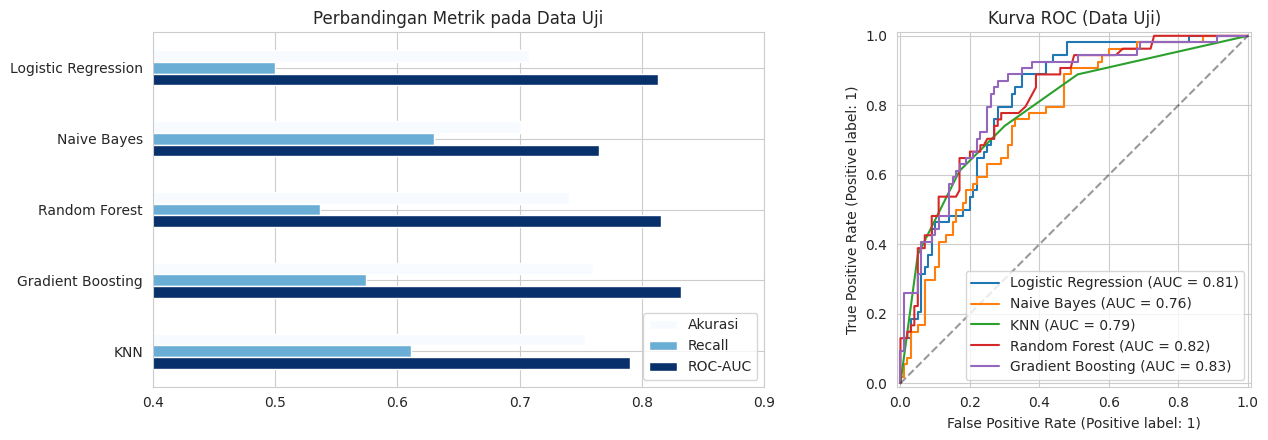

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

hasil_uji[["Akurasi", "Recall", "ROC-AUC"]].plot(kind="barh", ax=ax[0], colormap="Blues")
ax[0].set_title("Perbandingan Metrik pada Data Uji")
ax[0].set_xlim(0.4, 0.9); ax[0].invert_yaxis()

for nama, model in models.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=nama, ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[1].set_title("Kurva ROC (Data Uji)")
plt.tight_layout(); plt.show()

### 4.7 Optimasi Model Terbaik

Model terbaik dipilih berdasarkan **ROC-AUC validasi silang** (lebih adil dibanding satu kali uji). Dua perbaikan diterapkan:

1. **`class_weight="balanced"`** dan pencarian nilai `C` terbaik dengan `GridSearchCV`, agar kelas diabetes yang lebih sedikit mendapat perhatian lebih.
2. **Penyesuaian ambang keputusan (*threshold*)**. Secara bawaan, pasien diprediksi diabetes bila probabilitas ≥ 0,5. Untuk *screening*, ambang dapat diturunkan agar lebih banyak pasien berisiko tertangkap. Ambang dipilih **hanya dari data latih** (memakai prediksi validasi silang) dengan syarat recall minimal 80%, lalu diuji sekali pada data uji.

In [ ]:
model_terbaik = tabel_cv.index[0]
print("Model terbaik (berdasarkan CV ROC-AUC):", model_terbaik)

Model terbaik (berdasarkan CV ROC-AUC): Logistic Regression


In [ ]:
# Optimasi hiperparameter Logistic Regression (bila ini model terbaik, seperti pada hasil di atas)
pipe_lr = make_pipeline(imputer(), StandardScaler(),
                        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))

grid = GridSearchCV(pipe_lr, {"logisticregression__C": [0.01, 0.1, 1, 10, 100]},
                    cv=cv, scoring="roc_auc").fit(X_train, y_train)

final = grid.best_estimator_
print("C terbaik          :", grid.best_params_["logisticregression__C"])
print("CV ROC-AUC terbaik :", round(grid.best_score_, 4))

C terbaik          : 0.1
CV ROC-AUC terbaik : 0.845


In [ ]:
# Memilih ambang keputusan dari data latih (prediksi validasi silang)
prob_oof = cross_val_predict(final, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

ambang_uji = np.arange(0.20, 0.65, 0.05)
tabel_ambang = pd.DataFrame({
    "Ambang": ambang_uji.round(2),
    "Recall":    [recall_score(y_train, prob_oof >= t) for t in ambang_uji],
    "Precision": [precision_score(y_train, prob_oof >= t) for t in ambang_uji],
    "F1":        [f1_score(y_train, prob_oof >= t) for t in ambang_uji],
}).round(3).set_index("Ambang")
display(tabel_ambang)

# Ambang tertinggi yang masih memberi recall >= 80%
layak = tabel_ambang[tabel_ambang["Recall"] >= 0.80]
AMBANG = float(layak.index.max())
print("Ambang terpilih:", AMBANG)

,Recall,Precision,F1
Ambang,,,
0.20,0.986,0.454,0.622
0.25,0.963,0.489,0.649
0.30,0.911,0.500,0.646
0.35,0.883,0.543,0.673
0.40,0.822,0.564,0.669
0.45,0.794,0.599,0.683
0.50,0.720,0.650,0.683
0.55,0.668,0.681,0.675
0.60,0.626,0.724,0.672


Ambang terpilih: 0.4


### 4.8 Evaluasi Model Akhir pada Data Uji

In [ ]:
prob_uji = final.predict_proba(X_test)[:, 1]
pred_default = (prob_uji >= 0.5).astype(int)
pred_final   = (prob_uji >= AMBANG).astype(int)

perbandingan = pd.DataFrame({
    f"Ambang 0,50 (bawaan)": [accuracy_score(y_test, pred_default), precision_score(y_test, pred_default),
                              recall_score(y_test, pred_default), f1_score(y_test, pred_default)],
    f"Ambang {AMBANG:.2f} (terpilih)": [accuracy_score(y_test, pred_final), precision_score(y_test, pred_final),
                                        recall_score(y_test, pred_final), f1_score(y_test, pred_final)],
}, index=["Akurasi", "Precision (diabetes)", "Recall (diabetes)", "F1 (diabetes)"]).round(4)
print("ROC-AUC data uji model akhir:", round(roc_auc_score(y_test, prob_uji), 4))
perbandingan

ROC-AUC data uji model akhir: 0.8104


,"Ambang 0,50 (bawaan)",Ambang 0.40 (terpilih)
Akurasi,0.7078,0.7208
Precision (diabetes),0.5714,0.5696
Recall (diabetes),0.6667,0.8333
F1 (diabetes),0.6154,0.6767


In [ ]:
print(f"Laporan klasifikasi (ambang {AMBANG:.2f}):\n")
print(classification_report(y_test, pred_final, target_names=["Tidak diabetes", "Diabetes"]))

Laporan klasifikasi (ambang 0.40):



                precision    recall  f1-score   support

Tidak diabetes       0.88      0.66      0.75       100
      Diabetes       0.57      0.83      0.68        54

      accuracy                           0.72       154
     macro avg       0.72      0.75      0.72       154
  weighted avg       0.77      0.72      0.73       154



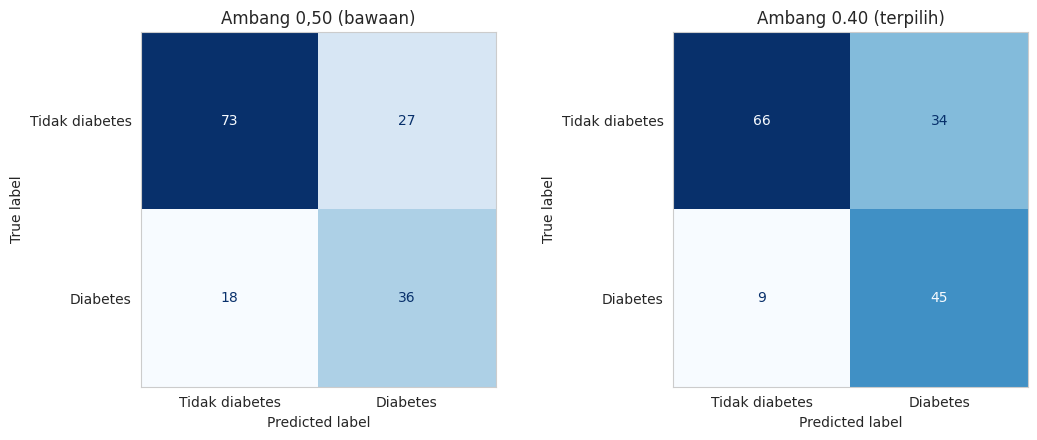

Dengan ambang 0.40:
  Sehat terdeteksi benar (TN)                 : 66
  Sehat salah dikira diabetes (FP)            : 34
  DIABETES SALAH DIKIRA SEHAT (FN)            : 9   <- kesalahan paling berbahaya
  Diabetes terdeteksi benar (TP)              : 45


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, pred, judul in zip(ax, [pred_default, pred_final],
                          ["Ambang 0,50 (bawaan)", f"Ambang {AMBANG:.2f} (terpilih)"]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Tidak diabetes", "Diabetes"]).plot(
        ax=a, cmap="Blues", values_format="d", colorbar=False)
    a.set_title(judul); a.grid(False)
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, pred_final).ravel()
print(f"Dengan ambang {AMBANG:.2f}:")
print(f"  Sehat terdeteksi benar (TN)                 : {tn}")
print(f"  Sehat salah dikira diabetes (FP)            : {fp}")
print(f"  DIABETES SALAH DIKIRA SEHAT (FN)            : {fn}   <- kesalahan paling berbahaya")
print(f"  Diabetes terdeteksi benar (TP)              : {tp}")

### 4.9 Fitur yang Paling Berpengaruh

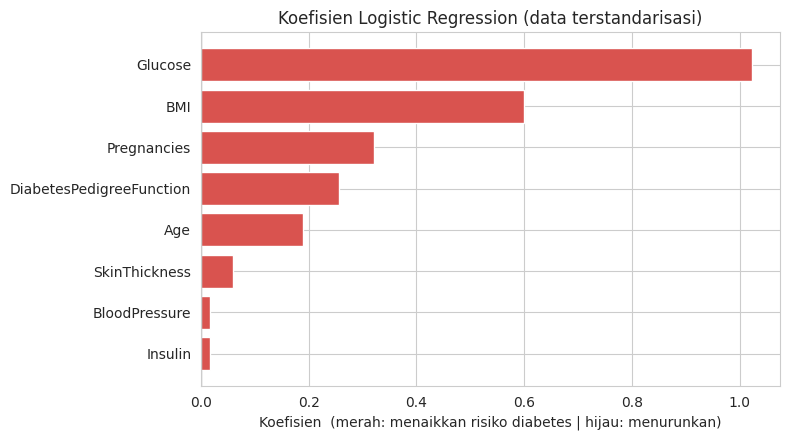

Glucose                     1.024
BMI                         0.599
Pregnancies                 0.321
DiabetesPedigreeFunction    0.256
Age                         0.189
SkinThickness               0.059
BloodPressure               0.017
Insulin                     0.016
dtype: float64

In [ ]:
koef = pd.Series(final.named_steps["logisticregression"].coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 4.5))
warna = ["#5cb85c" if v < 0 else "#d9534f" for v in koef.values]
plt.barh(koef.index, koef.values, color=warna)
plt.axvline(0, color="k", linewidth=0.8)
plt.title("Koefisien Logistic Regression (data terstandarisasi)")
plt.xlabel("Koefisien  (merah: menaikkan risiko diabetes | hijau: menurunkan)")
plt.tight_layout(); plt.show()

koef.sort_values(ascending=False).round(3)

## 5. Hasil dan Pembahasan

> Catatan: angka di bawah berasal dari satu kali eksekusi dengan `random_state=42`. Jika dijalankan ulang dengan versi *library* berbeda, angka dapat bergeser sedikit.

**Ringkasan hasil:**

| Aspek | Hasil |
|---|---|
| Model terbaik (CV ROC-AUC) | Logistic Regression (`class_weight="balanced"`, C = 0,1) |
| CV ROC-AUC | 0,845 |
| ROC-AUC data uji | 0,810 |
| Ambang keputusan terpilih | 0,40 (dipilih dari data latih) |
| Akurasi data uji | 72,1% |
| Recall diabetes pada data uji | 83,3% (45 dari 54 pasien diabetes terdeteksi) |
| Precision diabetes pada data uji | 57,0% |
| False negative (diabetes dikira sehat) | 9 pasien (turun dari 18 pada ambang 0,50) |
| False positive (sehat dikira diabetes) | 34 pasien |

**Pembahasan:**

1. **Kualitas data.** Tidak ada *missing value* yang terdeteksi secara teknis, tetapi ternyata banyak nilai 0 yang mustahil secara medis: 227 pasien (29,6%) pada `SkinThickness` dan 374 pasien (48,7%) pada `Insulin`. Jika nilai ini dibiarkan, model akan menganggapnya sebagai pengukuran asli. Mengubahnya menjadi data hilang lalu mengimputasi dengan median adalah langkah penting pada dataset ini.
2. **Perbandingan model.** Pada validasi silang, **Logistic Regression** unggul dengan ROC-AUC 0,843, disusul Naive Bayes (0,828) dan Random Forest (0,821). Model linear sederhana mengalahkan model yang lebih kompleks, kemungkinan karena data kecil (hanya 614 baris latih) dan hubungan antara fitur dan diabetes cukup mendekati linear.
3. **Hasil data uji bervariasi.** Pada satu kali pembagian, Gradient Boosting dan KNN tampak lebih baik dalam akurasi (sekitar 76% dan 75%) dibanding Logistic Regression (sekitar 71%). Karena data uji hanya 154 pasien, selisih beberapa pasien saja sudah mengubah angka beberapa persen. Itulah mengapa pemilihan model memakai validasi silang, bukan satu kali uji.
4. **Pengaruh ambang keputusan.** Dengan ambang bawaan 0,50, recall diabetes hanya 66,7% (18 pasien diabetes terlewat). Dengan menurunkan ambang ke 0,40, recall naik menjadi 83,3% dan yang terlewat tinggal 9 pasien. Harganya adalah jumlah *false positive* bertambah (precision 57%) dan akurasi hanya naik sedikit. Ini *trade-off* yang wajar untuk *screening*: pasien yang diprediksi berisiko dapat dikonfirmasi dengan pemeriksaan lanjutan, sedangkan pasien diabetes yang terlewat berisiko terlambat ditangani.
5. **Fitur berpengaruh.** Koefisien terbesar dimiliki `Glucose`, diikuti `BMI`, `Pregnancies`, dan `DiabetesPedigreeFunction`. Ini sejalan dengan pengetahuan medis bahwa kadar glukosa tinggi, kelebihan berat badan, dan riwayat keluarga meningkatkan risiko diabetes. Koefisien `Insulin` dan `SkinThickness` sangat kecil, kemungkinan karena hampir separuh nilainya hasil imputasi sehingga informasinya lemah.

**Keterbatasan:**
- Data hanya 768 pasien perempuan keturunan suku Pima berusia minimal 21 tahun, sehingga hasil belum tentu berlaku untuk populasi lain (termasuk laki-laki dan penduduk Indonesia).
- Akurasi sekitar 72% tergolong sedang; model ini belum layak dipakai sebagai alat keputusan tunggal.
- Evaluasi memakai satu kali pembagian data uji yang kecil, sehingga angka akhir memiliki ketidakpastian.
- Nilai yang hilang diisi median; metode imputasi lain (misalnya KNN imputer) dapat dicoba.
- Ambang 0,40 dipilih dengan syarat recall ≥ 80%; pemilihan syarat ini adalah keputusan subjektif yang sebaiknya ditentukan bersama tenaga medis.

## 6. Manfaat Penerapan

- **Penyaringan awal (*screening*) yang cepat:** model hanya membutuhkan 8 pengukuran klinis sederhana yang umum tersedia di fasilitas kesehatan tingkat pertama.
- **Prioritas pemeriksaan lanjutan:** pasien dengan probabilitas tinggi dapat didahulukan untuk tes konfirmasi (misalnya HbA1c atau glukosa puasa), sehingga sumber daya terbatas dipakai lebih efisien.
- **Deteksi dini dan pencegahan komplikasi:** pasien berisiko dapat diberi edukasi gaya hidup lebih awal.
- **Dapat dijelaskan:** Logistic Regression memberi koefisien yang bisa ditafsirkan tenaga kesehatan, bukan "kotak hitam".
- **Dapat disesuaikan:** ambang keputusan dapat diubah sesuai kebijakan, misalnya lebih sensitif saat kampanye *screening* massal.

## 7. Kesimpulan

Permasalahan klasifikasi risiko diabetes dapat didekati dengan *machine learning* menggunakan data klinis sederhana. Dari lima algoritma yang dibandingkan, **Logistic Regression** menjadi model terbaik berdasarkan validasi silang (ROC-AUC 0,845). Tahap preprocessing yang paling penting adalah mengenali nilai 0 tersembunyi sebagai data hilang, serta melakukan imputasi dan standardisasi di dalam *pipeline* untuk mencegah *data leakage*. Dengan menurunkan ambang keputusan menjadi 0,40, recall diabetes pada data uji meningkat dari 66,7% menjadi 83,3%, dengan konsekuensi lebih banyak *false positive*. Model ini cocok sebagai **alat bantu penyaringan awal**, bukan pengganti diagnosis dokter, dan perlu divalidasi pada data yang lebih besar dan lebih beragam sebelum dipakai secara nyata.

## 8. Referensi

1. National Institute of Diabetes and Digestive and Kidney Diseases. *Pima Indians Diabetes Database*. Tersedia di UCI Machine Learning Repository dan Kaggle: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
2. Smith, J. W., Everhart, J. E., Dickson, W. C., Knowler, W. C., & Johannes, R. S. (1988). Using the ADAP learning algorithm to forecast the onset of diabetes mellitus. *Proceedings of the Annual Symposium on Computer Application in Medical Care*, 261–265.
3. Brownlee, J. *Datasets* (salinan CSV terbuka `pima-indians-diabetes.data.csv`). GitHub: https://github.com/jbrownlee/Datasets
4. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
5. Dokumentasi scikit-learn: *Cross-validation*, *Tuning the decision threshold for class prediction*. https://scikit-learn.org/stable/